# Nigeria Inflation & Cost-of-Living Pulse

## Data cleaning

This notebook builds a clean monthly dataset for headline, food and core inflation from 2019 to the latest available month.

Cleaning decisions:

- Old-base workbooks supply 2019–2023 rates.
- The latest 2024-base workbook supplies 2024–2026 rates.
- Core inflation for 2019–2023 is calculated from the core CPI index in `Table2`.
- Index levels are labelled by base so that old-base and new-base levels are not mixed.
- Raw files are read only and are never modified.

In [1]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("..").resolve()
if not (PROJECT_DIR / "data").exists():
    PROJECT_DIR = Path(".").resolve()

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

print("Project: repository root")
print("Raw data:", RAW_DIR.relative_to(PROJECT_DIR))

Project: repository root
Raw data: data\raw


## Helper functions

The NBS workbooks store dates as a year label in one column and month names in another. Some monthly workbooks omit the year label after the first month, so the parser carries the year forward and increments it when January follows December.

In [2]:
MONTH_NAMES = {
    "january": 1, "jan": 1,
    "february": 2, "february": 2, "feb": 2, "febuary": 2,
    "march": 3, "mar": 3,
    "april": 4, "apr": 4,
    "may": 5,
    "june": 6, "jun": 6,
    "july": 7, "jul": 7,
    "august": 8, "aug": 8,
    "september": 9, "september": 9, "sept": 9, "sep": 9,
    "october": 10, "oct": 10,
    "november": 11, "nov": 11,
    "december": 12, "dec": 12,
}


def month_number(value):
    if pd.isna(value):
        return None
    text = str(value).lower()
    for name, number in MONTH_NAMES.items():
        if name in text:
            return number
    return None


def calendar_dates(raw, year_col, month_col):
    year = None
    previous_month = None
    dates = []
    for _, row in raw.iterrows():
        raw_year = row[year_col]
        explicit_year = pd.notna(raw_year) and str(raw_year).strip().isdigit()
        if explicit_year:
            year = int(raw_year)
        month = month_number(row[month_col])
        if not explicit_year and year is not None and previous_month == 12 and month == 1:
            year += 1
        dates.append(pd.Timestamp(year=year, month=month, day=1) if year and month else pd.NaT)
        if month:
            previous_month = month
    return pd.Series(dates)


def numeric(series):
    return pd.to_numeric(series, errors="coerce")

## Source files

Year-end workbooks are used for 2019–2023 because each one contains the complete set of months for that year. The October 2026 workbook is used for 2024–2026 because it contains the complete new-base back series through October 2026.

In [3]:
OLD_BASE_SOURCES = {
    2019: "CPI 2019/cpi_1NewDec2019.xlsx",
    2020: "CPI 2020/cpi_1NewDECEMBER2020.xls",
    2021: "CPI 2021/cpi_1NewDEC2021.xlsx",
    2022: "CPI 2022/cpi_1NewDEC2022.xlsx",
    2023: "CPI 2023/cpi_1NewDECEMBER2023.xlsx",
}

LATEST_SOURCE = "CPI 2026/cpi_1New_October2026.xlsx"

for relative_path in [*OLD_BASE_SOURCES.values(), LATEST_SOURCE]:
    path = RAW_DIR / relative_path
    if not path.exists():
        raise FileNotFoundError(path)

print(f"Old-base source files: {len(OLD_BASE_SOURCES)}")
print(f"Latest source file: {LATEST_SOURCE}")

Old-base source files: 5
Latest source file: CPI 2026/cpi_1New_October2026.xlsx


## Extract 2019–2023 from old-base workbooks

In the old layout:

- `Table1` column 5 contains headline YoY and column 15 contains food YoY.
- `Table2` column 4 contains the core CPI index.
- MoM and YoY core inflation are calculated from that index.

In [4]:
old_frames = []

for year, relative_path in OLD_BASE_SOURCES.items():
    path = RAW_DIR / relative_path
    table1 = pd.read_excel(path, sheet_name="Table1", header=None)
    table2 = pd.read_excel(path, sheet_name="Table2", header=None)

    dates1 = pd.to_datetime(calendar_dates(table1, 0, 1), errors="coerce")
    rates = pd.DataFrame({
        "date": dates1,
        "headline_index": numeric(table1[2]),
        "headline_mom": numeric(table1[4]),
        "headline_yoy": numeric(table1[5]),
        "food_index": numeric(table1[12]),
        "food_mom": numeric(table1[14]),
        "food_yoy": numeric(table1[15]),
    })
    rates = rates[rates["date"].dt.year == year]

    dates2 = pd.to_datetime(calendar_dates(table2, 0, 1), errors="coerce")
    core_index = numeric(table2[4])
    core = pd.DataFrame({
        "date": dates2,
        "core_index": core_index,
        "core_mom": core_index.pct_change(1, fill_method=None) * 100,
        "core_yoy": core_index.pct_change(12, fill_method=None) * 100,
    })
    core = core[core["date"].dt.year == year]

    frame = rates.merge(core, on="date", how="left")
    frame["index_base"] = "November 2009 = 100"
    frame["source_file"] = relative_path
    old_frames.append(frame)

old_monthly = pd.concat(old_frames, ignore_index=True)
old_monthly = old_monthly.sort_values("date").reset_index(drop=True)
old_monthly.head()

C:\Users\XPS\AppData\Local\Temp\ipykernel_20884\520673321.py:5: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  table1 = pd.read_excel(path, sheet_name="Table1", header=None)
C:\Users\XPS\AppData\Local\Temp\ipykernel_20884\520673321.py:6: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  table2 = pd.read_excel(path, sheet_name="Table2", header=None)


,date,headline_index,headline_mom,headline_yoy,food_index,food_mom,food_yoy,core_index,core_mom,core_yoy,index_base,source_file
0,2019-01-01,276.600688,0.737848,11.374083,298.850914,0.825843,13.505237,250.10,0.924095,10.622403,November 2009 = 100,CPI 2019/cpi_1NewDec2019.xlsx
1,2019-02-01,278.620148,0.730099,11.305853,301.297457,0.818650,13.473196,251.84,0.695722,10.531166,November 2009 = 100,CPI 2019/cpi_1NewDec2019.xlsx
2,2019-03-01,280.811771,0.786599,11.251150,303.942711,0.877954,13.451047,253.26,0.563850,10.237660,November 2009 = 100,CPI 2019/cpi_1NewDec2019.xlsx
3,2019-04-01,283.463033,0.944142,11.372068,307.395900,1.136132,13.701485,255.00,0.687041,9.942226,November 2009 = 100,CPI 2019/cpi_1NewDec2019.xlsx
4,2019-05-01,286.613329,1.111361,11.396405,311.733038,1.410929,13.794145,257.07,0.811765,9.638410,November 2009 = 100,CPI 2019/cpi_1NewDec2019.xlsx


## Extract 2024–2026 from the latest new-base workbook

The latest layout provides headline, food and core rates directly in `Table1`. The index base is 2024 = 100.

In [5]:
latest_path = RAW_DIR / LATEST_SOURCE
latest_table = pd.read_excel(latest_path, sheet_name="Table1", header=None)

new_monthly = pd.DataFrame({
    "date": pd.to_datetime(latest_table[22], errors="coerce"),
    "headline_index": numeric(latest_table[2]),
    "headline_mom": numeric(latest_table[4]),
    "headline_yoy": numeric(latest_table[5]),
    "food_index": numeric(latest_table[12]),
    "food_mom": numeric(latest_table[14]),
    "food_yoy": numeric(latest_table[15]),
    "core_index": numeric(latest_table[17]),
    "core_mom": numeric(latest_table[19]),
    "core_yoy": numeric(latest_table[20]),
})
new_monthly = new_monthly[new_monthly["date"] >= "2024-01-01"].copy()
new_monthly["index_base"] = "2024 = 100"
new_monthly["source_file"] = LATEST_SOURCE
new_monthly = new_monthly.sort_values("date").reset_index(drop=True)
new_monthly.head()

,date,headline_index,headline_mom,headline_yoy,food_index,food_mom,food_yoy,core_index,core_mom,core_yoy,index_base,source_file
0,2024-01-01,86.735631,2.640207,29.899059,85.114601,3.211921,35.413277,88.528224,2.240537,23.591767,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
1,2024-02-01,89.439520,3.117392,31.698232,88.340150,3.789654,37.919947,90.450650,2.171541,25.126898,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
2,2024-03-01,92.139727,3.019031,33.201433,91.534984,3.616515,40.014567,92.747380,2.539208,25.895484,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
3,2024-04-01,94.246835,2.286862,33.694665,93.827918,2.504980,40.530121,94.784061,2.195944,26.836636,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
4,2024-05-01,96.262679,2.138898,33.953014,95.971821,2.284932,40.661476,96.690977,2.011853,27.041417,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx


## Combine and validate

The cleaned series should contain one row per month from January 2019 to October 2026, with no missing headline, food or core inflation rates.

In [6]:
monthly = pd.concat([old_monthly, new_monthly], ignore_index=True)
duplicate_dates = int(monthly["date"].duplicated().sum())
monthly = monthly.drop_duplicates(subset="date", keep="last")
monthly = monthly.sort_values("date").set_index("date")

expected_dates = pd.date_range("2019-01-01", "2026-10-01", freq="MS")
missing_dates = expected_dates.difference(monthly.index)
extra_dates = monthly.index.difference(expected_dates)

rate_columns = [
    "headline_mom", "headline_yoy",
    "food_mom", "food_yoy",
    "core_mom", "core_yoy",
]

validation = {
    "rows": len(monthly),
    "first_month": monthly.index.min().strftime("%Y-%m"),
    "last_month": monthly.index.max().strftime("%Y-%m"),
    "duplicate_dates": duplicate_dates,
    "missing_months": [d.strftime("%Y-%m") for d in missing_dates],
    "extra_months": [d.strftime("%Y-%m") for d in extra_dates],
    "missing_rate_values": monthly[rate_columns].isna().sum().to_dict(),
}

validation

{'rows': 94,
 'first_month': '2019-01',
 'last_month': '2026-10',
 'duplicate_dates': 0,
 'missing_months': [],
 'extra_months': [],
 'missing_rate_values': {'headline_mom': 0,
  'headline_yoy': 0,
  'food_mom': 0,
  'food_yoy': 0,
  'core_mom': 0,
  'core_yoy': 0}}

In [7]:
if validation["rows"] != 94:
    raise ValueError("Expected 94 monthly rows")
if validation["duplicate_dates"] != 0:
    raise ValueError("Duplicate dates found")
if validation["missing_months"] or validation["extra_months"]:
    raise ValueError("Monthly coverage is incomplete")
if sum(validation["missing_rate_values"].values()) != 0:
    raise ValueError("Missing inflation rates found")

monthly.tail(12)

,headline_index,headline_mom,headline_yoy,food_index,food_mom,food_yoy,core_index,core_mom,core_yoy,index_base,source_file
date,,,,,,,,,,,
2025-11-01,130.466156,1.222869,17.327522,128.290000,1.127227,14.206094,132.027658,1.279271,20.588204,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
2025-12-01,131.166592,0.536872,15.150552,127.830000,-0.358563,10.844331,132.790000,0.577411,18.627797,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
2026-01-01,127.390000,-2.879233,15.097579,120.140000,-6.015802,8.891507,130.550000,-1.686874,17.718665,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
2026-02-01,129.950000,2.009577,15.061879,125.770000,4.686199,12.118032,131.710000,0.888548,15.879222,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
2026-03-01,135.384561,4.182040,15.378013,131.017005,4.171905,14.305536,137.013589,4.026717,16.211696,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
2026-04-01,138.270000,2.131291,15.687751,135.770000,3.627770,16.062575,138.420000,1.026476,15.857566,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
2026-05-01,140.683787,1.745706,15.932251,139.809861,2.975518,16.959627,141.108643,1.942380,16.822879,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
2026-06-01,143.020000,1.660613,15.908216,145.050000,3.748047,17.521361,143.457310,1.664439,15.918327,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
2026-07-01,145.268506,1.572162,15.429882,153.121650,5.564736,20.312446,143.672250,0.149829,14.974592,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx


## Save cleaned data

The cleaned monthly series is saved to `data/processed/monthly_inflation.csv`. This is a derived dataset; the original NBS workbooks remain untouched.

In [8]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
output_path = PROCESSED_DIR / "monthly_inflation.csv"
monthly.reset_index().to_csv(output_path, index=False)
print(f"Saved: {output_path.relative_to(PROJECT_DIR)}")

Saved: data\processed\monthly_inflation.csv


## Clean CPI divisions

`Table2` in the latest workbook contains index levels for 13 consumer divisions and their weights. Category inflation is calculated from the index levels, not copied from a separate rate column.

The division names are standardised here. Aggregates such as All Items, Food, Core, Services and Goods are excluded from the division ranking because they overlap with the division categories.

In [9]:
CATEGORY_COLUMNS = {
    14: "Food and non-alcoholic beverages",
    15: "Alcoholic beverages, tobacco and narcotics",
    16: "Clothing and footwear",
    17: "Housing, water, electricity, gas and other fuels",
    18: "Furnishings, household equipment and routine household maintenance",
    19: "Health",
    20: "Transport",
    21: "Information and communication",
    22: "Recreation, sport and culture",
    23: "Education services",
    24: "Restaurants and accommodation services",
    25: "Insurance and financial services",
    26: "Personal care, social protection and miscellaneous goods and services",
}

category_table = pd.read_excel(latest_path, sheet_name="Table2", header=None)
category_dates = pd.to_datetime(category_table[30], errors="coerce")

division_parts = []
for column, name in CATEGORY_COLUMNS.items():
    part = pd.DataFrame({
        "date": category_dates,
        "category": name,
        "weight": numeric(category_table.iloc[2, column]),
        "index": numeric(category_table[column]),
    })
    part = part.dropna(subset=["date", "index"])
    division_parts.append(part)

divisions = pd.concat(division_parts, ignore_index=True)
divisions = divisions.sort_values(["category", "date"]).reset_index(drop=True)
divisions["mom"] = divisions.groupby("category")["index"].pct_change(1, fill_method=None) * 100
divisions["yoy"] = divisions.groupby("category")["index"].pct_change(12, fill_method=None) * 100
divisions["index_base"] = "2024 = 100"
divisions["source_file"] = LATEST_SOURCE
divisions.head()

,date,category,weight,index,mom,yoy,index_base,source_file
0,2023-01-01,"Alcoholic beverages, tobacco and narcotics",0.37,74.682231,NaN,NaN,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
1,2023-02-01,"Alcoholic beverages, tobacco and narcotics",0.37,75.460701,1.042377,NaN,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
2,2023-03-01,"Alcoholic beverages, tobacco and narcotics",0.37,76.309871,1.125313,NaN,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
3,2023-04-01,"Alcoholic beverages, tobacco and narcotics",0.37,77.172255,1.130108,NaN,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx
4,2023-05-01,"Alcoholic beverages, tobacco and narcotics",0.37,78.015611,1.092823,NaN,2024 = 100,CPI 2026/cpi_1New_October2026.xlsx


## Validate CPI divisions

The division table should have one row per category and month. Missing values are expected before January 2024 because the new-base series starts in January 2023. Insurance and financial services starts only in January 2025, so its YoY rate starts in January 2026.

In [10]:
division_date_range = pd.date_range("2023-01-01", "2026-10-01", freq="MS")
expected_division_rows = len(CATEGORY_COLUMNS) * len(division_date_range)

division_validation = {
    "categories": divisions["category"].nunique(),
    "rows": len(divisions),
    "expected_rows_if_complete": expected_division_rows,
    "first_month": divisions["date"].min().strftime("%Y-%m"),
    "last_month": divisions["date"].max().strftime("%Y-%m"),
    "duplicate_category_months": int(divisions.duplicated(["category", "date"]).sum()),
    "missing_index_values": int(divisions["index"].isna().sum()),
    "missing_yoy_values": int(divisions["yoy"].isna().sum()),
    "weight_sum": round(divisions.groupby("category")["weight"].first().sum(), 2),
}

division_validation

{'categories': 13,
 'rows': 574,
 'expected_rows_if_complete': 598,
 'first_month': '2023-01',
 'last_month': '2026-10',
 'duplicate_category_months': 0,
 'missing_index_values': 0,
 'missing_yoy_values': 156,
 'weight_sum': np.float64(100.01)}

In [11]:
missing_yoy_by_category = (
    divisions.groupby("category")["yoy"]
    .apply(lambda series: int(series.isna().sum()))
    .sort_values(ascending=False)
)
missing_yoy_by_category

category
Alcoholic beverages, tobacco and narcotics                               12
Clothing and footwear                                                    12
Education services                                                       12
Food and non-alcoholic beverages                                         12
Furnishings, household equipment and routine household maintenance       12
Health                                                                   12
Housing, water, electricity, gas and other fuels                         12
Information and communication                                            12
Insurance and financial services                                         12
Personal care, social protection and miscellaneous goods and services    12
Recreation, sport and culture                                            12
Restaurants and accommodation services                                   12
Transport                                                                12
Nam

## Latest division snapshot

This table is used only to check that the cleaned division data is ready for analysis. Interpretation and rankings are handled in the exploratory analysis stage.

In [12]:
latest_division_date = divisions["date"].max()
latest_divisions = (
    divisions[divisions["date"] == latest_division_date]
    .sort_values("yoy", ascending=False)
    .reset_index(drop=True)
)
latest_divisions[["category", "weight", "index", "mom", "yoy"]]

,category,weight,index,mom,yoy
0,Restaurants and accommodation services,12.92,157.641988,1.544379,18.733139
1,Food and non-alcoholic beverages,40.02,149.362299,-0.060334,18.635662
2,"Housing, water, electricity, gas and other fuels",8.42,150.032348,1.966530,14.967316
3,"Personal care, social protection and miscellan...",3.29,153.534336,0.527486,12.257320
4,Transport,10.66,144.803732,1.864917,11.481817
5,Health,6.06,151.902405,-0.645906,9.613512
6,Education services,6.20,136.473333,-1.673779,7.105111
7,Information and communication,3.29,133.762768,1.180147,5.266993
8,"Recreation, sport and culture",0.31,117.654679,1.275243,4.461226
9,"Alcoholic beverages, tobacco and narcotics",0.37,132.376690,-0.275037,2.952784


In [13]:
if division_validation["categories"] != 13:
    raise ValueError("Expected 13 CPI divisions")
if division_validation["duplicate_category_months"] != 0:
    raise ValueError("Duplicate category-month rows found")
if division_validation["missing_index_values"] != 0:
    raise ValueError("Missing category index values found")
if division_validation["missing_yoy_values"] != 156:
    raise ValueError("Unexpected number of missing YoY values")

division_output_path = PROCESSED_DIR / "cpi_divisions.csv"
divisions.to_csv(division_output_path, index=False)
print(f"Saved: {division_output_path.relative_to(PROJECT_DIR)}")

Saved: data\processed\cpi_divisions.csv


## Exploratory analysis

The analysis uses inflation rates rather than index levels because NBS changed the CPI base year in 2024. Rates were checked against overlapping publications before combining them.

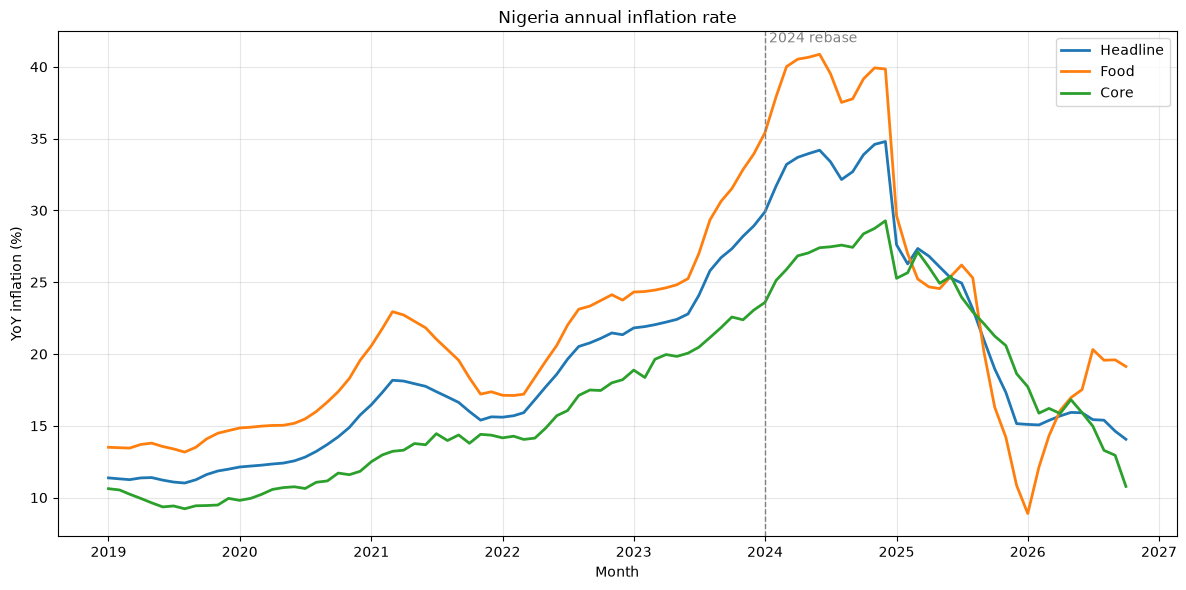

In [14]:
import matplotlib.pyplot as plt

FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(monthly.index, monthly["headline_yoy"], label="Headline", linewidth=2)
ax.plot(monthly.index, monthly["food_yoy"], label="Food", linewidth=2)
ax.plot(monthly.index, monthly["core_yoy"], label="Core", linewidth=2)
ax.axvline(pd.Timestamp("2024-01-01"), color="gray", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2024-01-01"), ax.get_ylim()[1], " 2024 rebase", color="gray", va="top")
ax.set_title("Nigeria annual inflation rate")
ax.set_ylabel("YoY inflation (%)")
ax.set_xlabel("Month")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "inflation_trends.png", dpi=160)
plt.show()

In [15]:
trend_summary = monthly[["headline_yoy", "food_yoy", "core_yoy"]].agg(
    ["mean", "median", "min", "max", "std"]
).T
trend_summary

,mean,median,min,max,std
headline_yoy,19.671010,17.355998,11.015909,34.796057,7.059450
food_yoy,22.236554,20.307636,8.891507,40.871046,8.243701
core_yoy,17.136739,15.868394,9.224142,29.276706,6.025608


## Category snapshot

The latest month is used to check which divisions are displayed clearly in a chart. Interpretation is kept for the written memo.

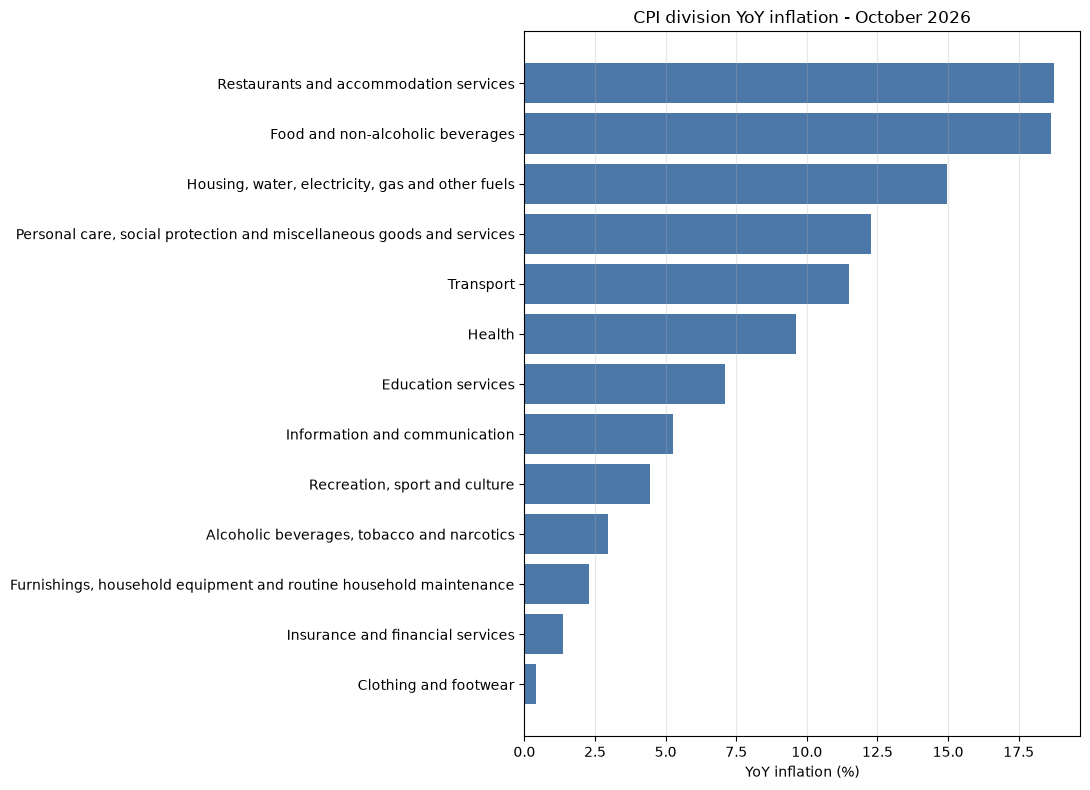

In [16]:
snapshot_date = divisions["date"].max()
snapshot = divisions[divisions["date"] == snapshot_date].sort_values("yoy")

fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(snapshot["category"], snapshot["yoy"], color="#4C78A8")
ax.set_title(f"CPI division YoY inflation - {snapshot_date:%B %Y}")
ax.set_xlabel("YoY inflation (%)")
ax.grid(True, axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "category_yoy_latest.png", dpi=160)
plt.show()

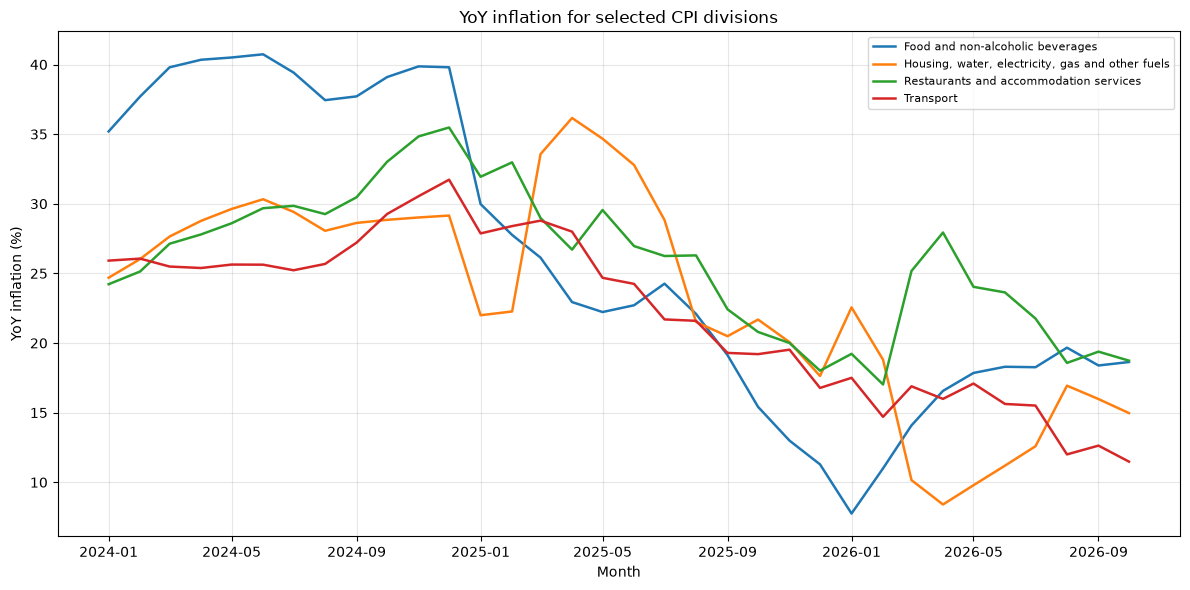

In [17]:
selected_categories = [
    "Food and non-alcoholic beverages",
    "Restaurants and accommodation services",
    "Housing, water, electricity, gas and other fuels",
    "Transport",
]
key_series = divisions[divisions["category"].isin(selected_categories)]

fig, ax = plt.subplots(figsize=(12, 6))
for category, group in key_series.groupby("category"):
    ax.plot(group["date"], group["yoy"], label=category, linewidth=1.8)
ax.set_title("YoY inflation for selected CPI divisions")
ax.set_ylabel("YoY inflation (%)")
ax.set_xlabel("Month")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "key_category_trends.png", dpi=160)
plt.show()

## Weighted contribution

Contribution is approximated as `(weight / 100) × category YoY rate`. Only months where all 13 divisions have YoY values are used. This starts in January 2026 because insurance and financial services begins in January 2025.

In [18]:
complete_counts = divisions.dropna(subset=["yoy"]).groupby("date")["category"].nunique()
complete_dates = complete_counts[complete_counts == len(CATEGORY_COLUMNS)].index

contributions = divisions[divisions["date"].isin(complete_dates)].copy()
contributions["contribution"] = contributions["weight"] / 100 * contributions["yoy"]
contributions = contributions[[
    "date", "category", "weight", "yoy", "contribution", "index_base", "source_file"
]]

contribution_output_path = PROCESSED_DIR / "category_contributions.csv"
contributions.to_csv(contribution_output_path, index=False)
print(f"Saved: {contribution_output_path.relative_to(PROJECT_DIR)}")

Saved: data\processed\category_contributions.csv


In [19]:
reconciliation = (
    contributions.groupby("date")["contribution"]
    .sum()
    .rename("estimated_headline_yoy")
    .reset_index()
)
reconciliation = reconciliation.merge(monthly.reset_index()[["date", "headline_yoy"]], on="date")
reconciliation["difference"] = reconciliation["estimated_headline_yoy"] - reconciliation["headline_yoy"]
print("Mean absolute gap:", round(reconciliation["difference"].abs().mean(), 3))
reconciliation

Mean absolute gap: 0.028


,date,estimated_headline_yoy,headline_yoy,difference
0,2026-01-01,15.118707,15.097579,0.021129
1,2026-02-01,15.077865,15.061879,0.015986
2,2026-03-01,15.379082,15.378013,0.001068
3,2026-04-01,15.781169,15.687751,0.093418
4,2026-05-01,15.986492,15.932251,0.054241
5,2026-06-01,15.945026,15.908216,0.036810
6,2026-07-01,15.420059,15.429882,-0.009822
7,2026-08-01,15.360772,15.390843,-0.030071
8,2026-09-01,14.629922,14.629617,0.000305
9,2026-10-01,14.080865,14.062538,0.018327


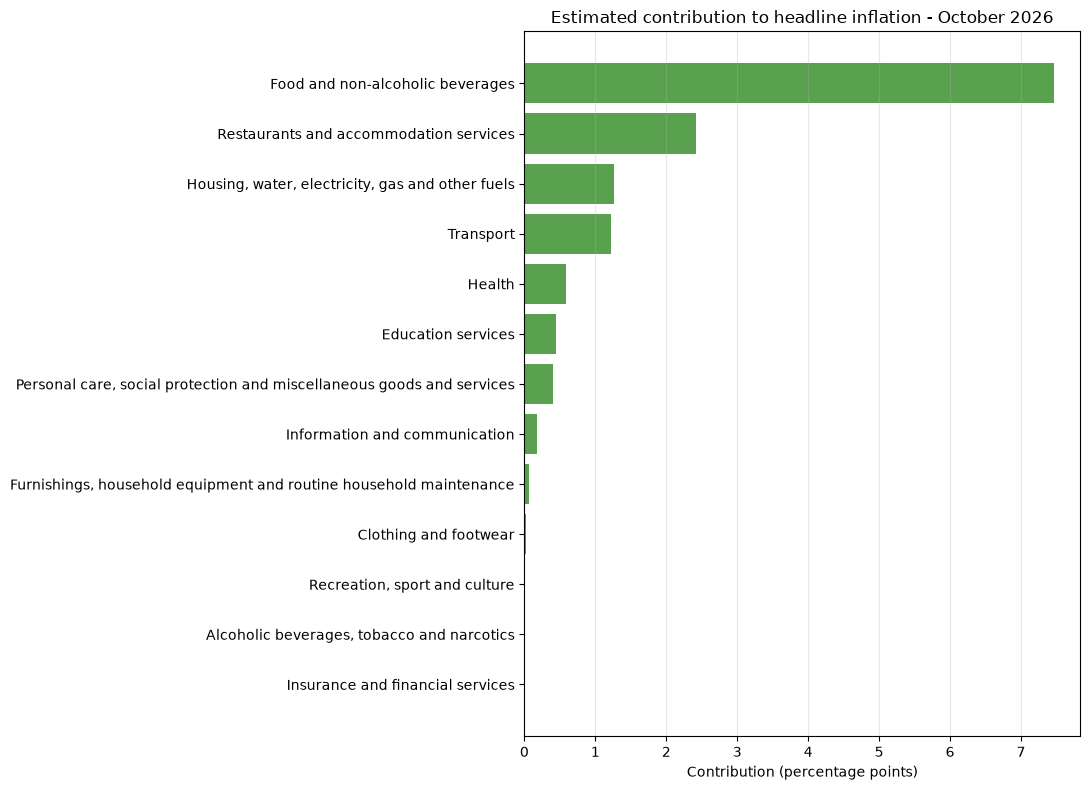

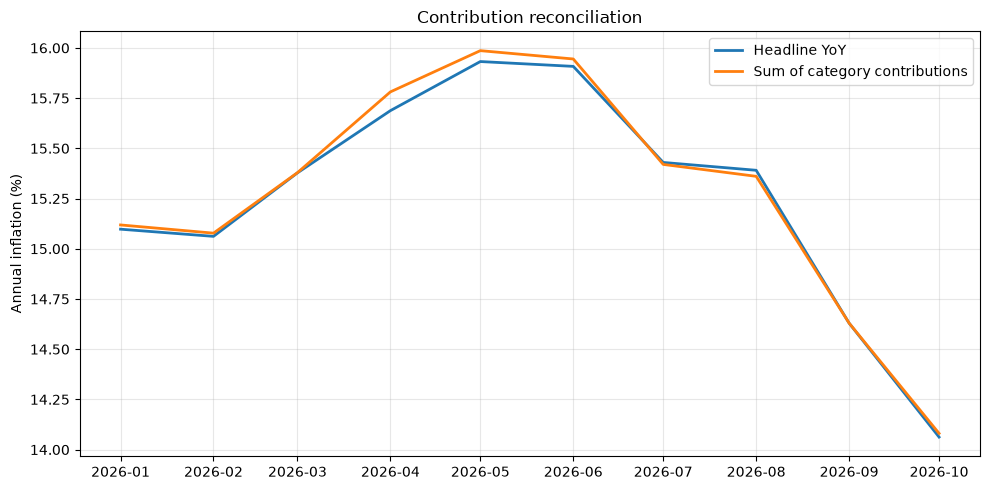

In [20]:
latest_contribution_date = contributions["date"].max()
latest_contribution = (
    contributions[contributions["date"] == latest_contribution_date]
    .sort_values("contribution")
)

fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(latest_contribution["category"], latest_contribution["contribution"], color="#59A14F")
ax.set_title(f"Estimated contribution to headline inflation - {latest_contribution_date:%B %Y}")
ax.set_xlabel("Contribution (percentage points)")
ax.grid(True, axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "weighted_contribution_latest.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(reconciliation["date"], reconciliation["headline_yoy"], label="Headline YoY", linewidth=2)
ax.plot(reconciliation["date"], reconciliation["estimated_headline_yoy"], label="Sum of category contributions", linewidth=2)
ax.set_title("Contribution reconciliation")
ax.set_ylabel("Annual inflation (%)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "contribution_reconciliation.png", dpi=160)
plt.show()

## Concepts used in this stage

- **CPI index vs inflation rate:** the index is a price level; inflation is its percentage change.
- **MoM vs YoY:** MoM compares with the previous month; YoY compares with the same month a year earlier.
- **Core inflation for 2019–2023:** calculated from the core index because those `Table1` sheets do not label a core rate directly.
- **Rebasing:** the index base changes from November 2009 = 100 to 2024 = 100. Index levels are therefore labelled, while inflation rates remain comparable after validation.

## Category concepts

- **Category inflation rate:** percentage change in a category's CPI index.
- **Weight:** the share of that category in the CPI basket.
- **Inflation rate vs contribution:** a high inflation rate does not automatically mean a large contribution; contribution also depends on weight.
- **Missing data:** new categories introduced later cannot have YoY rates until 12 months of index values exist.

## Analysis concepts

- **YoY inflation:** percentage change from the same month in the previous year.
- **MoM inflation:** percentage change from the previous month.
- **Weighted contribution:** an estimate of how many percentage points a category adds to headline inflation.
- **Reconciliation:** the sum of category contributions should be close to headline inflation when the same basket weights and complete categories are used.